# =========================================================
# RAIL DEFECT SEGMENTATION & SEVERITY PIPELINE (SINGLE FILE)
# Model: U-Net with EfficientNet-B0
# Task : Binary segmentation (class-wise folders)
# Class - SShelling and Black Spots
# =========================================================

STEP 0️⃣ – GLOBAL SETTINGS (RUN FIRST)

In [1]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 16.1 MB/s eta 0:00:00


In [2]:
import os
import cv2
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp


In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_DEFECT = "Shelling and Black Spots"
EPOCHS = 20
BATCH_SIZE = 4
LR = 1e-4


✅ Verify

In [4]:
print("Device:", DEVICE)
print("Target defect:", TARGET_DEFECT)


Device: cuda
Target defect: Shelling and Black Spots


STEP 1️⃣ – DATASET CLASS (NO AUGMENTATION YET)

STEP 2️⃣ – DISPLAY FEW SAMPLES AFTER LOADING DATASET ✅ (POINT 1)

In [5]:
import os, cv2, torch, numpy as np
from torch.utils.data import Dataset

class RailDataset(Dataset):
    def __init__(self, defect_path, transform=None, skip_empty_masks=True):
        self.defect_path = defect_path
        self.image_dir = os.path.join(defect_path, "Images")
        self.mask_dir  = os.path.join(defect_path, "masks")
        self.transform = transform

        self.images = []

        for f in sorted(os.listdir(self.image_dir)):
            if not f.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            img_path  = os.path.join(self.image_dir, f)
            name, _   = os.path.splitext(f)
            mask_path = os.path.join(self.mask_dir, name + ".png")

            if not os.path.exists(mask_path):
                continue

            if skip_empty_masks:
                mask = cv2.imread(mask_path, 0)
                if mask is None or np.sum(mask) == 0:
                    continue

            self.images.append(img_path)

        print(f"Loaded {len(self.images)} non-empty mask samples")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        img_name = os.path.basename(img_path)
        name, _ = os.path.splitext(img_name)

        mask_path = os.path.join(self.mask_dir, name + ".png")

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, 0)
        if mask is None:
            raise FileNotFoundError(f"Mask missing for {img_name}")

        mask = (mask > 0).astype("float32")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
        else:
            image = torch.from_numpy(image).permute(2,0,1).float()

        mask = torch.tensor(mask).unsqueeze(0)

        return image, mask, img_name


In [6]:
def show_samples(dataset, n=3):
    plt.figure(figsize=(8, 3*n))

    for i in range(n):
        img, mask, _ = dataset[i]   # unpack image, mask, filename

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img.permute(1,2,0).numpy() / 255.0)  # ✅ FIX
        plt.title("Image")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask.squeeze(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.show()




Loaded 175 non-empty mask samples


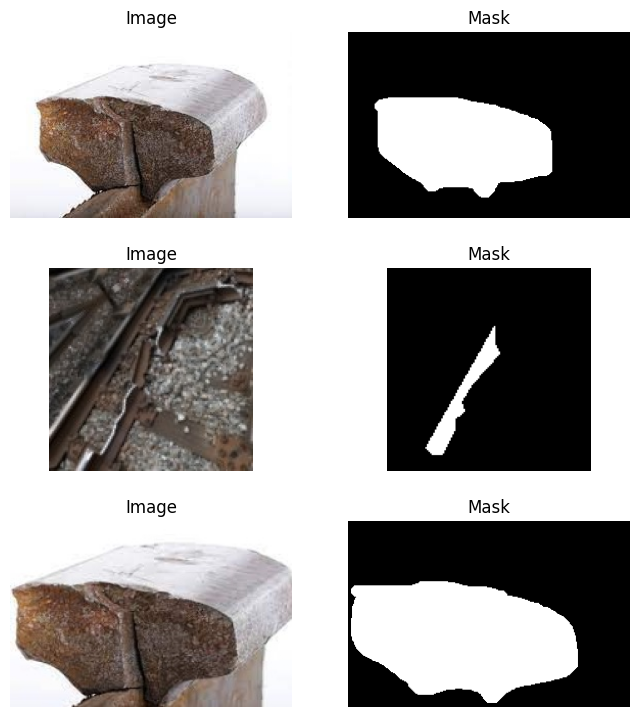

In [8]:
train_defect_path = "/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Shelling and Black Spots"

train_ds_plain = RailDataset(train_defect_path)
show_samples(train_ds_plain)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


STEP 3️⃣ – ENVIRONMENT-WISE DATA AUGMENTATION + DISPLAY ✅ (POINT 2)

Morning

In [9]:
# -------------------------
# Sample environmental augmentations
# -------------------------
aug_rain = A.Compose([
    A.RandomRain(p=1.0)
])

aug_fog = A.Compose([
    A.RandomFog(
        fog_coef_lower=0.3,
        fog_coef_upper=0.6,
        alpha_coef=0.1,
        p=1.0
    )
])

aug_snow = A.Compose([
    A.RandomSnow(
        snow_point_lower=0.1,
        snow_point_upper=0.3,
        brightness_coeff=1.5,
        p=1.0
    )
])

# -------------------------
# Sample lighting augmentations
# -------------------------
aug_morning = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(0.1, 0.3),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_evening = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.3, -0.1),
        contrast_limit=(0, 0.1),
        p=1.0
    )
])

aug_night = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=(-0.5, -0.3),
        contrast_limit=(0.1, 0.3),
        p=1.0
    )
])


/tmp/ipykernel_1809/830839087.py:9: UserWarning: Argument(s) 'fog_coef_lower, fog_coef_upper' are not valid for transform RandomFog
  A.RandomFog(
/tmp/ipykernel_1809/830839087.py:18: UserWarning: Argument(s) 'snow_point_lower, snow_point_upper' are not valid for transform RandomSnow
  A.RandomSnow(


In [10]:
def show_augmentations(dataset, aug_list, titles):
    img, mask, _ = dataset[0]

    # Convert tensor → numpy uint8 (Albumentations needs this)
    img = img.permute(1,2,0).numpy()
    img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)

    mask = mask.squeeze().numpy().astype(np.uint8)

    plt.figure(figsize=(18, 3))

    for i, aug in enumerate(aug_list):
        out = aug(image=img, mask=mask)

        aug_img = out["image"].astype(np.float32) / 255.0  # for display

        plt.subplot(1, len(aug_list), i+1)
        plt.imshow(aug_img)
        plt.title(titles[i])
        plt.axis("off")

    plt.show()



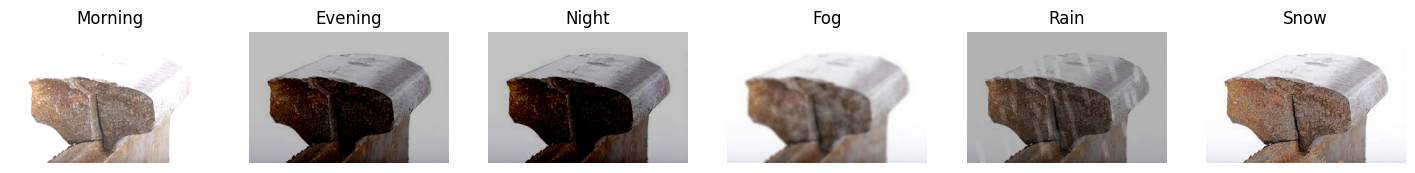

In [11]:
show_augmentations(
    train_ds_plain,
    [aug_morning, aug_evening, aug_night, aug_fog, aug_rain, aug_snow],
    ["Morning", "Evening", "Night", "Fog", "Rain", "Snow"]
)

STEP 4️⃣ – FINAL TRANSFORMS & LOADERS

In [12]:
from albumentations.pytorch import ToTensorV2

train_tfms = A.Compose([
    A.Resize(512, 512),

    A.HorizontalFlip(p=0.5),

    A.OneOf([
        aug_morning,
        aug_evening,
        aug_night,
        aug_fog,
        aug_rain
    ], p=0.7),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()   # ✅ THIS IS THE KEY FIX
])



In [13]:
val_tfms = A.Compose([
    A.Resize(512, 512),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


In [14]:
train_ds = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Training Set/Shelling and Black Spots", train_tfms)
val_ds   = RailDataset("/content/drive/MyDrive/Severity Calculation Data Set/With Split/Validation Set/Shelling and Black Spots", val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Train samples:", len(train_ds))
print("Val samples:", len(val_ds))


Loaded 175 non-empty mask samples
Loaded 37 non-empty mask samples
Train samples: 175
Val samples: 37


HOW TO VERIFY AUGMENTATION IS REALLY APPLIED (VISUAL PROOF)

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def show_augmented_samples(dataset, n=3):
    plt.figure(figsize=(8, 4*n))

    for i in range(n):
        img, mask, name = dataset[i]

        # ---------- IMAGE ----------
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu()
            img = img.permute(1, 2, 0).numpy()
        elif isinstance(img, np.ndarray):
            if img.ndim == 3:
                pass
            else:
                raise ValueError("Unexpected image shape")

        # Normalize only for display
        img = img - img.min()
        if img.max() > 0:
            img = img / img.max()

        # ---------- MASK ----------
        if isinstance(mask, torch.Tensor):
            mask = mask.detach().cpu().squeeze().numpy()
        elif isinstance(mask, np.ndarray):
            mask = mask.squeeze()

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(img)
        plt.title(f"Augmented Image\n{name}")
        plt.axis("off")

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(mask, cmap="gray")
        plt.title("Mask")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


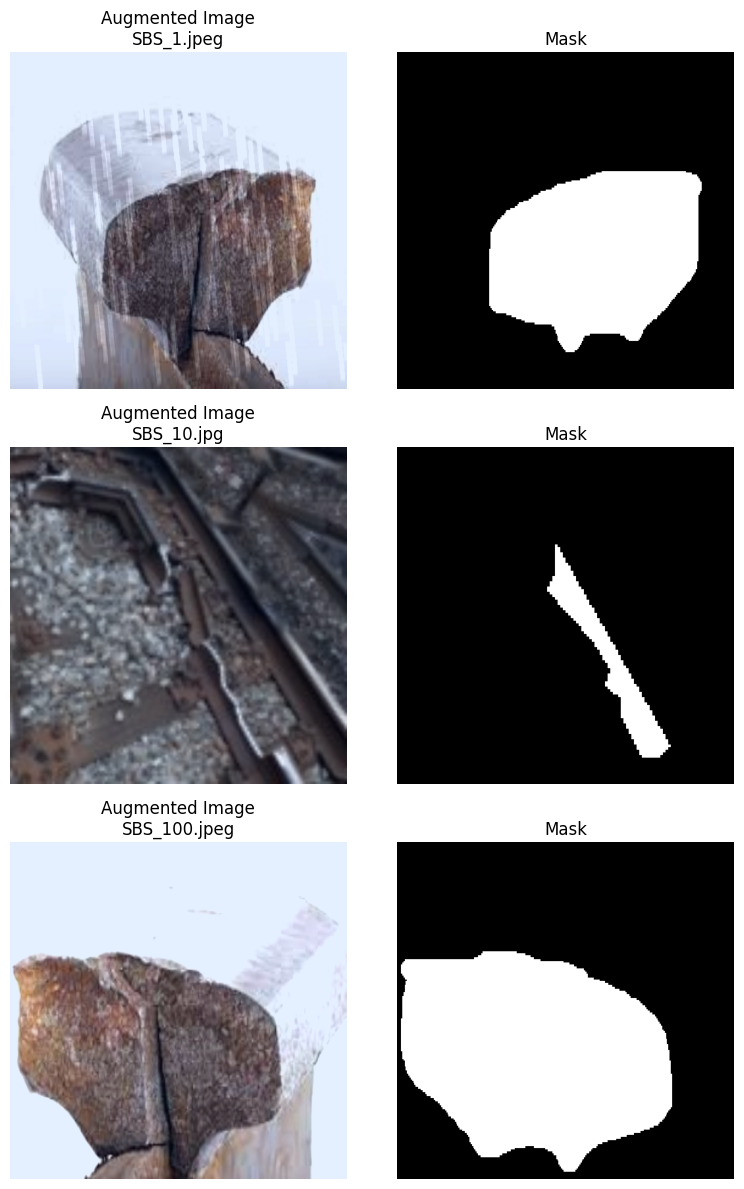

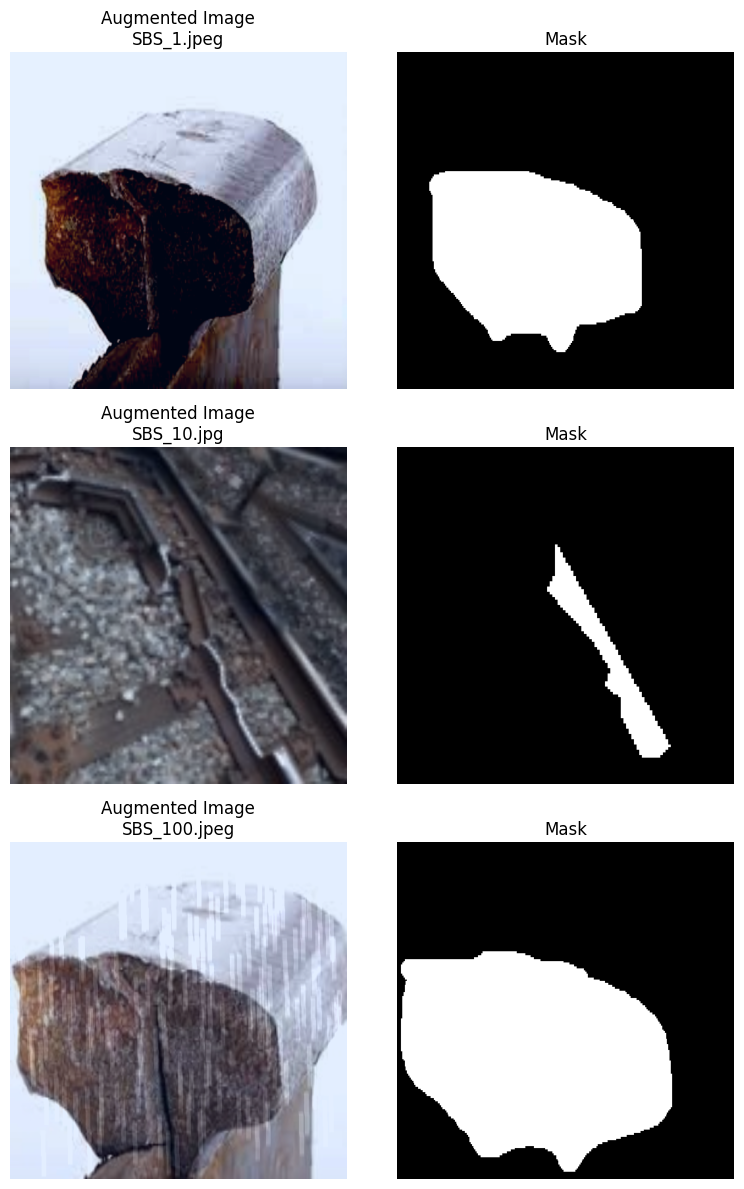

In [16]:
show_augmented_samples(train_ds)
show_augmented_samples(train_ds)


STEP 5️⃣ – MODEL, LOSS, METRICS ✅ (POINT 3)

In [17]:
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

In [18]:
from scipy.ndimage import distance_transform_edt

def boundary_loss(pred, gt):
    """
    Normalized boundary loss (stable).
    """
    gt_np = gt.detach().cpu().numpy()

    # Distance transform
    dist = distance_transform_edt(1 - gt_np)

    # Normalize distance map to [0,1]
    dist = dist / (dist.max() + 1e-8)

    dist = torch.tensor(dist, device=pred.device).float()

    pred = torch.sigmoid(pred)

    return (pred * dist).mean()




In [19]:
# =========================
# OPTION 2: FOCAL TVERSKY LOSS
# =========================

bce = nn.BCEWithLogitsLoss()

tversky = smp.losses.TverskyLoss(
    mode="binary",
    alpha=0.7,
    beta=0.3
)

def loss_fn(pred, gt):
    return (
        0.50 * bce(pred, gt) +
        0.40 * tversky(pred, gt) +
        0.10 * boundary_loss(pred, gt)
    )




In [20]:
def dice_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum()
    return (2*inter + eps) / (union + eps)


Hausdorff distance

In [21]:
from scipy.spatial.distance import directed_hausdorff
import numpy as np


In [22]:
def hausdorff_distance(pred_mask, gt_mask):
    """
    Computes symmetric Hausdorff Distance (in pixels)
    pred_mask, gt_mask: binary numpy arrays (H,W)
    """
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    # If either mask is empty, HD is undefined → return large value
    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    hd1 = directed_hausdorff(pred_pts, gt_pts)[0]
    hd2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return max(hd1, hd2)


STEP 6️⃣ – TRAINING + ALL METRICS + RUNTIME ✅ (POINT 4)

6.1 METRIC FUNCTIONS (ADD ONCE)

In [23]:
def iou_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + eps) / (union + eps)

def pixel_accuracy(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    correct = (pred == gt).float().sum()
    total = torch.numel(pred)
    return correct / total

def precision_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fp = (pred * (1 - gt)).sum()
    return (tp + eps) / (tp + fp + eps)

def recall_score(pred, gt, eps=1e-7):
    pred = (torch.sigmoid(pred) > 0.5).float()
    tp = (pred * gt).sum()
    fn = ((1 - pred) * gt).sum()
    return (tp + eps) / (tp + fn + eps)


6.2 HISTORY DICTIONARY (FOR CURVES LATER)

In [24]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    #verbose=True
)


start_time = time.time()



In [25]:
history = {
    # Loss
    "train_loss": [],
    "val_loss": [],

    # Dice & IoU
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": [],

    # Accuracy / Precision / Recall
    "train_acc": [],
    "val_acc": [],
    "train_prec": [],
    "val_prec": [],
    "train_rec": [],
    "val_rec": [],

    # Hausdorff
    "train_hd": [],
    "val_hd": []
}


In [26]:
best_val_dice = 0.0
epoch_times = []
total_training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0

    train_hd = []

    for imgs, masks, _ in train_loader:   # ✅ FIXED
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


        # Hausdorff (TRAIN)
        preds_bin = (torch.sigmoid(preds) > 0.5).float()
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i, 0].cpu().numpy()
            gt_np   = masks[i, 0].cpu().numpy()
            hd = hausdorff_distance(pred_np, gt_np)
            if not np.isnan(hd):
                train_hd.append(hd)

    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)

    mean_train_hd = np.mean(train_hd) if len(train_hd) > 0 else np.nan
    history["train_hd"].append(mean_train_hd)

    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:   # ✅ FIXED
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            # Hausdorff (VAL)
            preds_bin = (torch.sigmoid(preds) > 0.5).float()
            for i in range(preds_bin.size(0)):
                pred_np = preds_bin[i, 0].cpu().numpy()
                gt_np   = masks[i, 0].cpu().numpy()
                hd = hausdorff_distance(pred_np, gt_np)
                if not np.isnan(hd):
                    val_hd.append(hd)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_val_hd = np.mean(val_hd) if len(val_hd) > 0 else np.nan
    history["val_hd"].append(mean_val_hd)

    scheduler.step(vd)

    # ================= SAVE HISTORY =================
    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_dice"].append(td)
    history["val_dice"].append(vd)
    history["train_iou"].append(ti)
    history["val_iou"].append(vi)
    history["train_acc"].append(tacc)
    history["val_acc"].append(vacc)
    history["train_prec"].append(tprec)
    history["val_prec"].append(vprec)
    history["train_rec"].append(trec)
    history["val_rec"].append(vrec)





    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_dice": best_val_dice,
            "architecture": "Unet++",
            "encoder": "efficientnet-b0",
            "defect": "Rail Wear",
            "image_size": 512
        }
        torch.save(checkpoint, "best_unetpp_effb0_SBS.pth")

    # ================= RUNTIME =================
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)

    # ================= PRINT METRICS (COMPLETE) =================
    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )


# ================= TOTAL TIME =================
total_training_time = time.time() - total_training_start
print("Total training time:", total_training_time)
print("Avg epoch time:", sum(epoch_times) / len(epoch_times))




/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 112.8s
  Train → Loss=0.5771, Dice=0.3862, IoU=0.2485, Acc=0.6677, Prec=0.3735, Rec=0.4495, HD=278.82px
  Val   → Loss=0.5317, Dice=0.5470, IoU=0.3903, Acc=0.6833, Prec=0.4136, Rec=0.9015, HD=274.23px

Epoch [2/20] | Time 65.1s
  Train → Loss=0.4648, Dice=0.5855, IoU=0.4219, Acc=0.7984, Prec=0.6036, Rec=0.6171, HD=273.09px
  Val   → Loss=0.3928, Dice=0.7250, IoU=0.5776, Acc=0.8732, Prec=0.6600, Rec=0.8354, HD=273.26px

Epoch [3/20] | Time 66.9s
  Train → Loss=0.3860, Dice=0.6880, IoU=0.5363, Acc=0.8547, Prec=0.7179, Rec=0.7337, HD=268.66px
  Val   → Loss=0.3179, Dice=0.7840, IoU=0.6521, Acc=0.9110, Prec=0.7917, Rec=0.8067, HD=268.07px

Epoch [4/20] | Time 235.9s
  Train → Loss=0.3322, Dice=0.7466, IoU=0.6116, Acc=0.8818, Prec=0.7704, Rec=0.7711, HD=254.86px
  Val   → Loss=0.2840, Dice=0.8080, IoU=0.6847, Acc=0.9187, Prec=0.8149, Rec=0.8302, HD=237.16px

Epoch [5/20] | Time 171.0s
  Train → Loss=0.3210, Dice=0.7440, IoU=0.6130, Acc=0.8840, Prec=0.7640, Rec=0.8077, HD

ADD THIS FUNCTION (RUN AFTER TRAINING)

In [27]:
import numpy as np
import torch

def find_best_iou_threshold(model, val_loader):
    model.eval()
    thresholds = np.arange(0.4, 0.8, 0.05)

    best_iou = 0.0
    best_t = 0.5

    with torch.no_grad():
        for t in thresholds:
            iou_sum = 0.0

            for imgs, masks, _ in val_loader:   # ✅ FIX HERE
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                probs = torch.sigmoid(model(imgs))
                preds = (probs > t).float()
                iou_sum += iou_score(preds, masks).item()

            mean_iou = iou_sum / len(val_loader)

            print(f"Threshold {t:.2f} → IoU {mean_iou:.4f}")

            if mean_iou > best_iou:
                best_iou = mean_iou
                best_t = t

    print(f"\n✔ Best threshold = {best_t:.2f}, IoU = {best_iou:.4f}")
    return best_t, best_iou


In [28]:
best_t, best_iou = find_best_iou_threshold(model, val_loader)



/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Threshold 0.40 → IoU 0.7847
Threshold 0.45 → IoU 0.7828
Threshold 0.50 → IoU 0.7800
Threshold 0.55 → IoU 0.7760
Threshold 0.60 → IoU 0.7709
Threshold 0.65 → IoU 0.7640
Threshold 0.70 → IoU 0.7546
Threshold 0.75 → IoU 0.7406

✔ Best threshold = 0.40, IoU = 0.7847


STEP 7️⃣ – ACCURACY & LOSS CURVES ✅ (POINT 5)

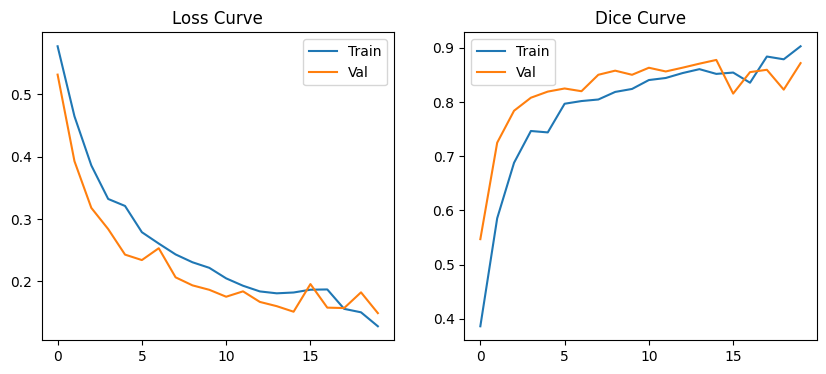

In [29]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_dice"], label="Train")
plt.plot(history["val_dice"], label="Val")
plt.title("Dice Curve")
plt.legend()
plt.show()




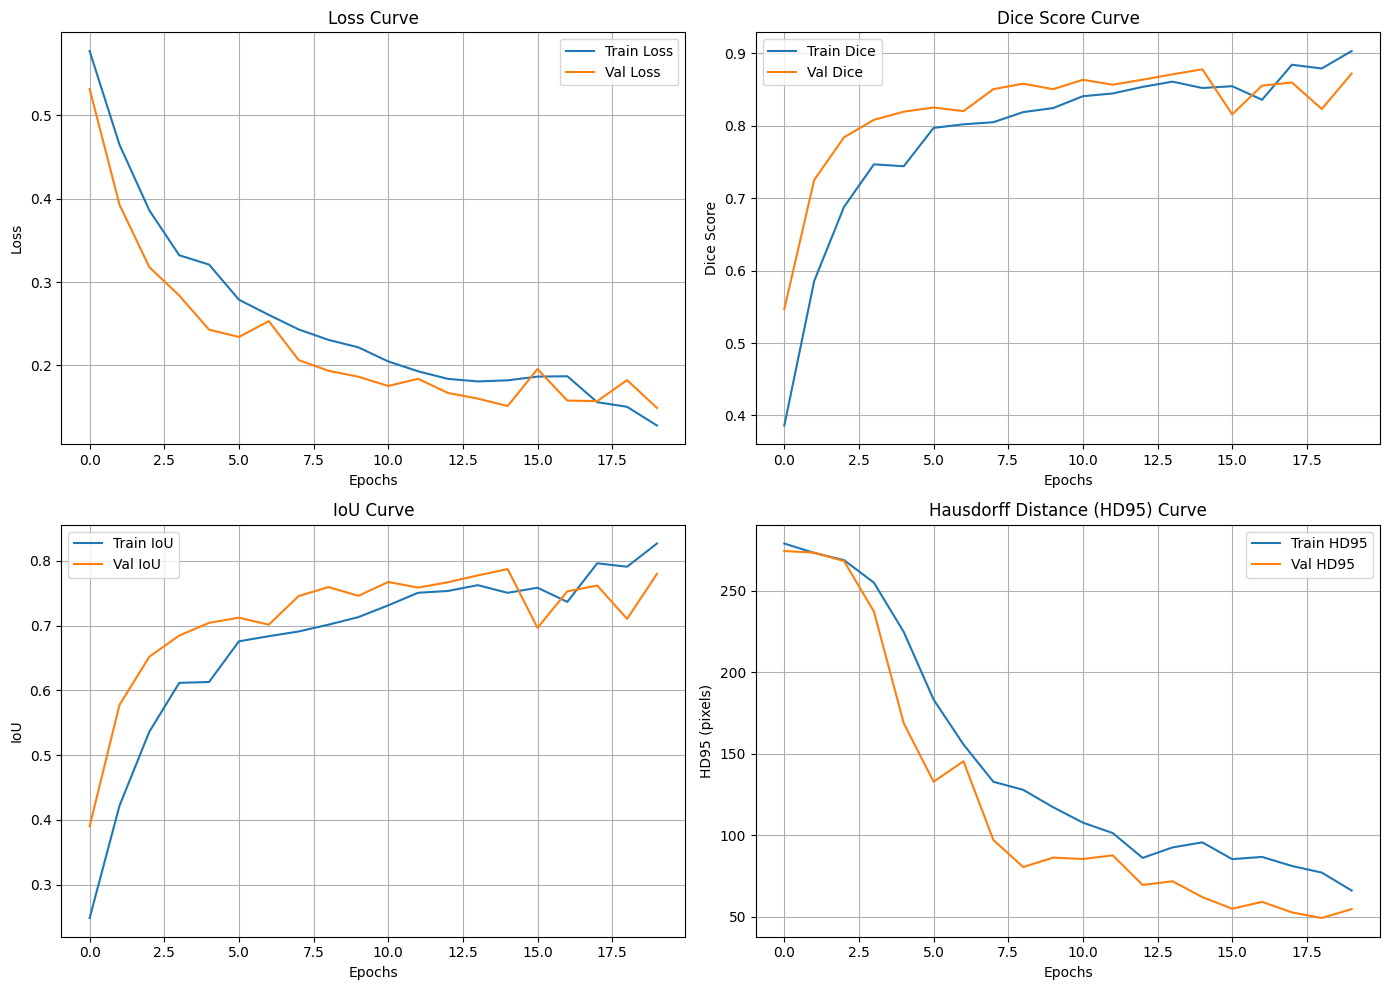

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# ---------------- Loss Curve ----------------
plt.subplot(2, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------------- Dice Curve ----------------
plt.subplot(2, 2, 2)
plt.plot(history["train_dice"], label="Train Dice")
plt.plot(history["val_dice"], label="Val Dice")
plt.title("Dice Score Curve")
plt.xlabel("Epochs")
plt.ylabel("Dice Score")
plt.legend()
plt.grid(True)

# ---------------- IoU Curve ----------------
plt.subplot(2, 2, 3)
plt.plot(history["train_iou"], label="Train IoU")
plt.plot(history["val_iou"], label="Val IoU")
plt.title("IoU Curve")
plt.xlabel("Epochs")
plt.ylabel("IoU")
plt.legend()
plt.grid(True)

# ---------------- Hausdorff Distance Curve ----------------
plt.subplot(2, 2, 4)
plt.plot(history["train_hd"], label="Train HD95")
plt.plot(history["val_hd"], label="Val HD95")
plt.title("Hausdorff Distance (HD95) Curve")
plt.xlabel("Epochs")
plt.ylabel("HD95 (pixels)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


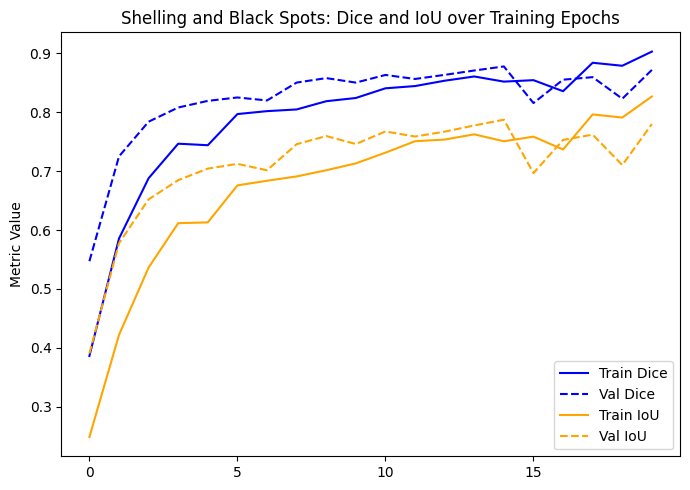

In [31]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Shelling and Black Spots: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()



Apply CRF post-processing once

In [32]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.spatial.distance import directed_hausdorff



In [33]:
def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


In [34]:
best_val_dice = 0.0
epoch_times = []
total_start = time.time()


#BEST_MODEL_PATH = "/content/unetpp_efficientnetb0_SBS_best.pth"

for epoch in range(EPOCHS):
    start = time.time()

    # ================= TRAIN =================
    model.train()
    tl = td = ti = tacc = tprec = trec = 0.0


    for imgs, masks , _ in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tl += loss.item()
        td += dice_score(preds, masks).item()
        ti += iou_score(preds, masks).item()
        tacc  += pixel_accuracy(preds, masks).item()
        tprec += precision_score(preds, masks).item()
        trec  += recall_score(preds, masks).item()


    tl /= len(train_loader)
    td /= len(train_loader)
    ti /= len(train_loader)
    tacc  /= len(train_loader)
    tprec /= len(train_loader)
    trec  /= len(train_loader)


    # ================= VALIDATION =================
    model.eval()
    vl = vd = vi = vacc = vprec = vrec = 0.0
    val_hd95 = []

    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs)

            vl += loss_fn(preds, masks).item()
            vd += dice_score(preds, masks).item()
            vi += iou_score(preds, masks).item()
            vacc += pixel_accuracy(preds, masks).item()
            vprec += precision_score(preds, masks).item()
            vrec += recall_score(preds, masks).item()

            probs = torch.sigmoid(preds)

            for i in range(imgs.size(0)):
                 pred_bin = (probs[i,0] > 0.5).cpu().numpy()
                 gt_np    = masks[i,0].cpu().numpy()

                 hd95 = hausdorff_distance_95(pred_bin, gt_np)
                 if not np.isnan(hd95):
                     val_hd95.append(hd95)

    vl /= len(val_loader)
    vd /= len(val_loader)
    vi /= len(val_loader)
    vacc /= len(val_loader)
    vprec /= len(val_loader)
    vrec /= len(val_loader)
    mean_hd95 = np.mean(val_hd95)

    # ================= SAVE BEST MODEL =================
    if vd > best_val_dice:
        best_val_dice = vd
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "best_val_dice": best_val_dice
        }, "best_unetpp_effb0_SCB.pth")

    epoch_time = time.time() - start
    epoch_times.append(epoch_time)

    print(
    f"Epoch [{epoch+1}/{EPOCHS}] | Time {epoch_time:.1f}s\n"
    f"  Train → Loss={tl:.4f}, Dice={td:.4f}, IoU={ti:.4f}, "
    f"Acc={tacc:.4f}, Prec={tprec:.4f}, Rec={trec:.4f}, HD={mean_train_hd:.2f}px\n"
    f"  Val   → Loss={vl:.4f}, Dice={vd:.4f}, IoU={vi:.4f}, "
    f"Acc={vacc:.4f}, Prec={vprec:.4f}, Rec={vrec:.4f}, HD={mean_val_hd:.2f}px\n"
    )

print("\nTotal training time:", time.time() - total_start)
print("Avg epoch time:", sum(epoch_times)/len(epoch_times))


/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


Epoch [1/20] | Time 52.8s
  Train → Loss=0.1358, Dice=0.8913, IoU=0.8104, Acc=0.9515, Prec=0.8980, Rec=0.8983, HD=66.14px
  Val   → Loss=0.1580, Dice=0.8582, IoU=0.7595, Acc=0.9405, Prec=0.9147, Rec=0.8157, HD=54.76px

Epoch [2/20] | Time 95.9s
  Train → Loss=0.1526, Dice=0.8728, IoU=0.7890, Acc=0.9474, Prec=0.8667, Rec=0.9086, HD=66.14px
  Val   → Loss=0.1438, Dice=0.8714, IoU=0.7784, Acc=0.9460, Prec=0.9036, Rec=0.8483, HD=54.76px

Epoch [3/20] | Time 54.2s
  Train → Loss=0.1290, Dice=0.8995, IoU=0.8223, Acc=0.9551, Prec=0.8972, Rec=0.9092, HD=66.14px
  Val   → Loss=0.1485, Dice=0.8723, IoU=0.7800, Acc=0.9460, Prec=0.9055, Rec=0.8478, HD=54.76px

Epoch [4/20] | Time 72.6s
  Train → Loss=0.1254, Dice=0.9027, IoU=0.8251, Acc=0.9545, Prec=0.9139, Rec=0.8972, HD=66.14px
  Val   → Loss=0.1535, Dice=0.8650, IoU=0.7697, Acc=0.9419, Prec=0.8923, Rec=0.8459, HD=54.76px

Epoch [5/20] | Time 115.4s
  Train → Loss=0.1391, Dice=0.8896, IoU=0.8122, Acc=0.9488, Prec=0.8961, Rec=0.9052, HD=66.14px
 

Save Model

In [37]:
import torch

# --------------------------------------------------
# SAVE TRAINED UNet++ EfficientNet-B0 MODEL
# --------------------------------------------------

SAVE_PATH = "best_unet_effb0_SBS.pth"

# Save only the model weights (best practice)
torch.save(model.state_dict(), SAVE_PATH)

print("✅ Trained model saved successfully")
print("📁 Model path:", SAVE_PATH)


✅ Trained model saved successfully
📁 Model path: best_unet_effb0_SBS.pth


Draw Graph

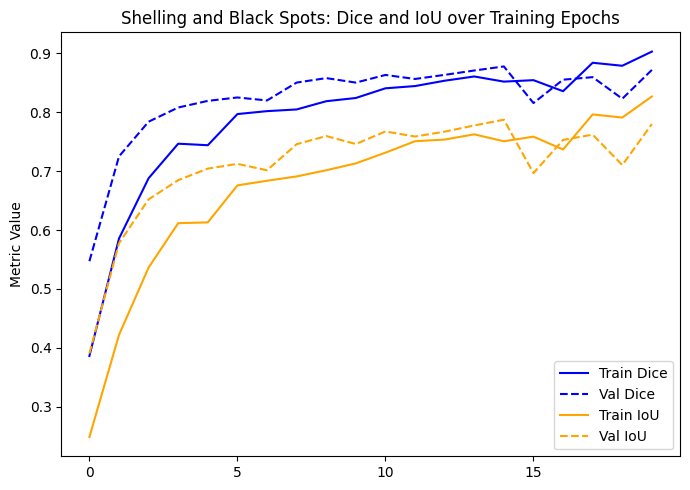

In [38]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(len(history["train_dice"]))

plt.figure(figsize=(7,5))

# Dice
plt.plot(epochs, history["train_dice"], label="Train Dice", color="blue", linestyle="-")
plt.plot(epochs, history["val_dice"], label="Val Dice", color="blue", linestyle="--")

# IoU
plt.plot(epochs, history["train_iou"], label="Train IoU", color="orange", linestyle="-")
plt.plot(epochs, history["val_iou"], label="Val IoU", color="orange", linestyle="--")

plt.title("Shelling and Black Spots: Dice and IoU over Training Epochs")
plt.xticks(np.arange(0, len(epochs), 5))
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()


Run on Test Data

STEP 1 — LOAD BEST TRAINED MODEL

In [39]:
import torch

# --------------------------------------------------
# LOAD TRAINED UNet++ EfficientNet-B0 MODEL (Rail Wear)
# --------------------------------------------------

MODEL_PATH = "best_unet_effb0_SBS.pth"

# Load state_dict
state_dict = torch.load(MODEL_PATH, map_location=DEVICE)

# Load into model
model.load_state_dict(state_dict)

# Set to evaluation mode
model.to(DEVICE)
model.eval()

print("✔ Trained Rail Wear model loaded successfully")


✔ Trained Rail Wear model loaded successfully


STEP 2 — TEST DATASET & LOADER

In [40]:
TEST_PATH = (
    "/content/drive/MyDrive/Severity Calculation Data Set/With Split/Test Set/Shelling and Black Spots"
)

test_ds = RailDataset(TEST_PATH, transform=val_tfms)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print("Test samples:", len(test_ds))


Loaded 37 non-empty mask samples
Test samples: 37


STEP 3 — HD95 FUNCTION (ROBUST & FINAL)

In [41]:
from scipy.spatial.distance import directed_hausdorff

def hausdorff_distance_95(pred_mask, gt_mask):
    pred_pts = np.argwhere(pred_mask > 0)
    gt_pts   = np.argwhere(gt_mask > 0)

    if len(pred_pts) == 0 or len(gt_pts) == 0:
        return np.nan

    d1 = directed_hausdorff(pred_pts, gt_pts)[0]
    d2 = directed_hausdorff(gt_pts, pred_pts)[0]

    return np.percentile([d1, d2], 95)


STEP 4 — RUN MODEL ON TEST DATA (CORE)

In [42]:
test_dice = test_iou = test_acc = test_prec = test_rec = 0.0
test_hd95 = []

with torch.no_grad():
    for imgs, masks, img_names in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        preds = model(imgs)
        probs = torch.sigmoid(preds)
        preds_bin = (probs > 0.5).float()

        test_dice += dice_score(preds, masks).item()
        test_iou  += iou_score(preds, masks).item()
        test_acc  += pixel_accuracy(preds, masks).item()
        test_prec += precision_score(preds, masks).item()
        test_rec  += recall_score(preds, masks).item()

        # HD95 (per image)
        for i in range(preds_bin.size(0)):
            pred_np = preds_bin[i,0].cpu().numpy()
            gt_np   = masks[i,0].cpu().numpy()

            hd95 = hausdorff_distance_95(pred_np, gt_np)
            if not np.isnan(hd95):
                test_hd95.append(hd95)

# Averages
test_dice /= len(test_loader)
test_iou  /= len(test_loader)
test_acc  /= len(test_loader)
test_prec /= len(test_loader)
test_rec  /= len(test_loader)
mean_test_hd95 = np.mean(test_hd95)


/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)


STEP 5 — PRINT FINAL TEST RESULTS (PAPER-READY)

In [43]:
print("\n========== FINAL TEST RESULTS ==========")
print(f"Dice Score       : {test_dice:.4f}")
print(f"IoU              : {test_iou:.4f}")
print(f"Accuracy         : {test_acc:.4f}")
print(f"Precision        : {test_prec:.4f}")
print(f"Recall           : {test_rec:.4f}")
print(f"HD95 (pixels)    : {mean_test_hd95:.2f}")



========== FINAL TEST RESULTS ==========
Dice Score       : 0.8734
IoU              : 0.7779
Accuracy         : 0.9391
Precision        : 0.9063
Recall           : 0.8497
HD95 (pixels)    : 71.00


STEP 1 — SEVERITY CALCULATION FUNCTION (FINAL)

Severity Visualization and Recommended Action

– VISUALIZATION + ACTION RECOMMENDATION (ONE BLOCK)

In [44]:
def visualize_shelling_blackspot_images_only(
    images,
    gt_masks,
    pred_masks,
    max_samples=5
):
    import matplotlib.pyplot as plt
    import numpy as np
    import cv2

    n = min(len(images), max_samples)

    plt.figure(figsize=(15, 3 * n))

    for i in range(n):

        # Original image
        img = images[i].permute(1, 2, 0).cpu().numpy()
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)

        plt.subplot(n, 3, i * 3 + 1)
        plt.imshow(img)
        plt.title("Original Image")
        plt.axis("off")

        # Ground truth
        gt = gt_masks[i].cpu().numpy()
        gt = gt[0] if gt.ndim == 3 else gt
        gt = (gt > 0).astype(np.uint8)

        plt.subplot(n, 3, i * 3 + 2)
        plt.imshow(gt, cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # Prediction + severity
        pred = pred_masks[i].cpu().numpy()
        pred = pred[0] if pred.ndim == 3 else pred
        pred = (pred > 0).astype(np.uint8)

        area_percent = (np.sum(pred) / pred.size) * 100
        num_labels, _ = cv2.connectedComponents(pred)
        num_regions = max(num_labels - 1, 0)

        if area_percent < 2 and num_regions <= 2:
            severity = "Low"
            action = "Monitor closely"
        elif area_percent < 8 or num_regions > 2:
            severity = "Moderate"
            action = "Planned maintenance / rail grinding"
        else:
            severity = "Severe"
            action = "Urgent rail grinding / renewal"

        plt.subplot(n, 3, i * 3 + 3)
        plt.imshow(pred, cmap="gray")
        plt.title(
            f"Predicted Mask\n"
            f"Severity: {severity} | Area: {area_percent:.2f}%\n"
            f"Action: {action}",
            color="red"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [45]:
def visualize_shelling_blackspot_with_filelist(
    model,
    dataloader,
    device,
    max_samples=5
):
    model.eval()

    # Fetch one batch
    images, gt_masks, image_names = next(iter(dataloader))

    # Print file list separately
    print("\nSelected image files for visualization:")
    for i, name in enumerate(image_names[:max_samples]):
        print(f"{i+1}. {name}")

    # Inference
    with torch.no_grad():
        preds = model(images.to(device))
        preds = torch.sigmoid(preds)
        preds = (preds > 0.5).float()

    # Visualization (NO filenames inside)
    visualize_shelling_blackspot_images_only(
        images=images.cpu(),
        gt_masks=gt_masks.cpu(),
        pred_masks=preds.cpu(),
        max_samples=max_samples
    )


/tmp/ipykernel_1809/2864647272.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask).unsqueeze(0)



Selected image files for visualization:
1. SBS_176.jpg
2. SBS_177.jpg
3. SBS_178.jpeg
4. SBS_179.jpeg


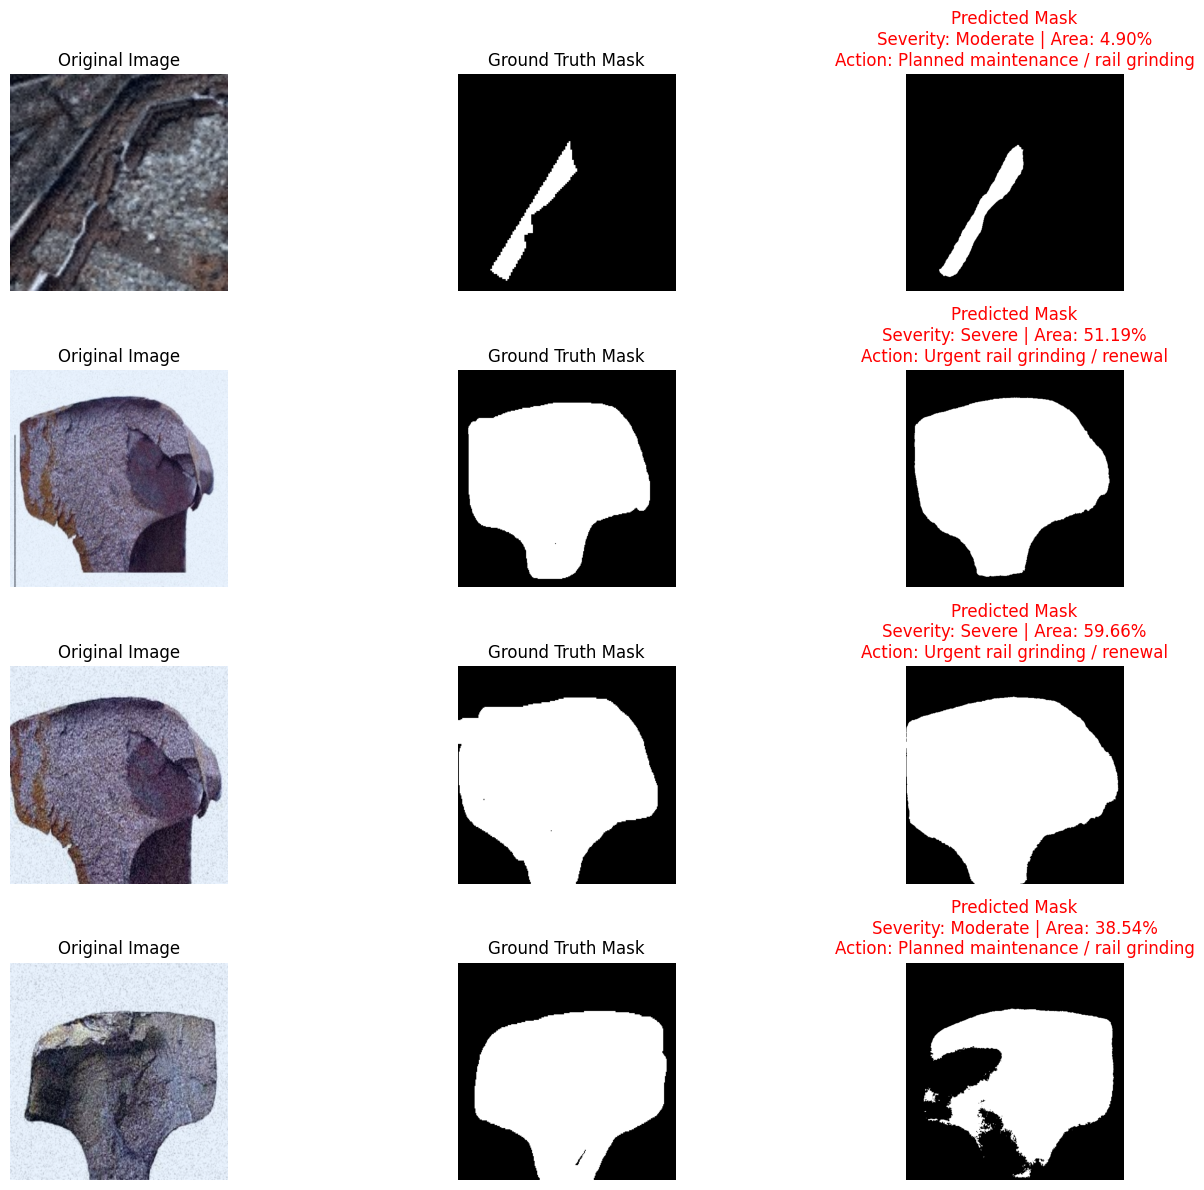

In [46]:
visualize_shelling_blackspot_with_filelist(
    model=model,
    dataloader=val_loader,
    device=DEVICE,
    max_samples=5
)


STEP 1: EXTRACT FINAL / BEST VALUES AUTOMATICALLY

In [49]:
import numpy as np

# Convert to numpy array of floats (handles tensors & NaNs)
val_dice = np.array([
    float(v) if v is not None else np.nan
    for v in history["val_dice"]
])


In [50]:
best_epoch = int(np.argmax(history["val_dice"]))

In [51]:
print("Best Epoch (1-based):", best_epoch + 1)
print("Best Val Dice:", history["val_dice"][best_epoch])


Best Epoch (1-based): 15
Best Val Dice: 0.8777865469455719


In [52]:
for k, v in history.items():
    print(k, len(v))


train_loss 20
val_loss 20
train_dice 20
val_dice 20
train_iou 20
val_iou 20
train_acc 20
val_acc 20
train_prec 20
val_prec 20
train_rec 20
val_rec 20
train_hd 20
val_hd 20


In [53]:
train_metrics = {
    "Dice": history["train_dice"][best_epoch],
    "IoU": history["train_iou"][best_epoch],
    "Accuracy": history.get("train_acc", [None])[best_epoch],
    "Precision": history.get("train_prec", [None])[best_epoch],
    "Recall": history.get("train_rec", [None])[best_epoch],
    "HD95": history["train_hd"][best_epoch]
}

val_metrics = {
    "Dice": history["val_dice"][best_epoch],
    "IoU": history["val_iou"][best_epoch],
    "Accuracy": history["val_acc"][best_epoch],
    "Precision": history["val_prec"][best_epoch],
    "Recall": history["val_rec"][best_epoch],
    "HD95": history["val_hd"][best_epoch]
}
test_metrics = {
    "Dice": test_dice,
    "IoU": test_iou,
    "Accuracy": test_acc,
    "Precision": test_prec,
    "Recall": test_rec,
    "HD95": test_hd95
}


In [54]:
best_train_epoch = int(np.nanargmax(history["train_dice"]))

train_metrics_best = {
    "Dice": history["train_dice"][best_train_epoch],
    "IoU": history["train_iou"][best_train_epoch],
    "Precision": history["train_prec"][best_train_epoch],
    "Recall": history["train_rec"][best_train_epoch],
    "HD95": history["train_hd"][best_train_epoch],
}


STEP 2: BUILD RESULTS TABLE AUTOMATICALLY (NO MANUAL VALUES)

In [55]:
import numpy as np
import pandas as pd

test_hd95_mean = float(np.mean(test_metrics["HD95"]))

results_table = pd.DataFrame({
    "Dataset Split": ["Training", "Validation", "Test"],
    "Dice Score": [
        round(train_metrics["Dice"], 4),
        round(val_metrics["Dice"], 4),
        round(test_metrics["Dice"], 4)
    ],
    "IoU": [
        round(train_metrics["IoU"], 4),
        round(val_metrics["IoU"], 4),
        round(test_metrics["IoU"], 4)
    ],
    "Accuracy": [
        round(train_metrics["Accuracy"], 4),
        round(val_metrics["Accuracy"], 4),
        round(test_metrics["Accuracy"], 4)
    ],
    "Precision": [
        round(train_metrics["Precision"], 4),
        round(val_metrics["Precision"], 4),
        round(test_metrics["Precision"], 4)
    ],
    "Recall": [
        round(train_metrics["Recall"], 4),
        round(val_metrics["Recall"], 4),
        round(test_metrics["Recall"], 4)
    ],
    "HD95 (pixels)": [
        round(train_metrics["HD95"], 2),
        round(val_metrics["HD95"], 2),
        round(test_hd95_mean, 2)
    ]
})

results_table



,Dataset Split,Dice Score,IoU,Accuracy,Precision,Recall,HD95 (pixels)
0,Training,0.8520,0.7507,0.9332,0.8536,0.8754,95.67
1,Validation,0.8778,0.7873,0.9486,0.8892,0.8724,62.12
2,Test,0.8734,0.7779,0.9391,0.9063,0.8497,71.00
